In [3]:
import xarray as xr
import pandas as pd
import rasterio
from rasterio.mask import mask
from rasterio.transform import from_bounds
import rioxarray
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from glob import glob

In [24]:
main_data_folder = "/Users/yihua/Desktop/花花Catherine/大学（UCSB）/活动相关/UCSB DS/Genhack/Data/"

In [5]:
country_code = "ESP" # Germany
cityname = "Barcelona"

In [131]:
ndvi_data_folder = main_data_folder + "sentinel_ndvi/ndvi_"

def quarter2timeperiod(year, quarter):
    if quarter == 1:
        return f"{year-1}-12-01_{year}-03-01"
    elif quarter == 2:
        return f"{year}-03-01_{year}-06-01"
    elif quarter == 3:
        return f"{year}-06-01_{year}-09-01"
    elif quarter == 4:
        return f"{year}-09-01_{year}-12-01"
    else:
        raise ValueError("quarter must be in 1, 2, 3, 4")

In [156]:
available_years = [2020, 2021, 2022, 2023]
available_quarters = [1, 2, 3, 4]

In [157]:
year = 2023
quarter = 4

In [159]:
timeperiod = quarter2timeperiod(year, quarter)

filepath  = f"{ndvi_data_folder}ndvi_{timeperiod}.tif"

In [64]:
def convert_ndvi_to_real_scale(ndvi_img, out_meta):
    # The NDVI is stored in int8 format on a 0/254 scale, and nodata is 255.
    # This function converts it to a float format on a -1/1 scale, and replace nodata with np.nan.
    ndvi_img = ndvi_img.astype(float)
    ndvi_img[ndvi_img == out_meta["nodata"]] = np.nan
    ndvi_img = ndvi_img / 254 * 2 - 1
    return ndvi_img

def get_out_image_and_metadata(filepath, one_city_gdf):
    with rasterio.open(filepath) as src:
        one_city_gdf_in_good_crs = one_city_gdf.to_crs(src.crs)
        city_geometry = [one_city_gdf_in_good_crs.geometry.iloc[0]]
        out_image, out_transform = mask(src, city_geometry, crop=True)
        out_meta = src.meta

        out_meta.update({
            "height": out_image.shape[1],
            "width": out_image.shape[2],
            "transform": out_transform
        })

        real_out_image = convert_ndvi_to_real_scale(out_image, out_meta)

    return real_out_image, out_meta

In [28]:
gadm_filepath = main_data_folder + "gadm_410_europe.gpkg"

In [29]:
gadm_gdf = gpd.read_file("/Users/yihua/Desktop/花花Catherine/大学（UCSB）/活动相关/UCSB DS/Genhack/Data/gadm_410_europe.gpkg")

print(f"Number of rows in GADM: {len(gadm_gdf)}")
gadm_gdf.head()

Number of rows in GADM: 106252


,UID,GID_0,NAME_0,GID_1,NAME_1,ENGTYPE_1,GID_2,NAME_2,ENGTYPE_2,GID_3,...,ENGTYPE_3,GID_4,NAME_4,ENGTYPE_4,GID_5,NAME_5,ENGTYPE_5,COUNTRY,CONTINENT,geometry
0,333,ALA,Åland,ALA.1_2,Archipelago,Sub-Region,ALA.1.1_2,Brändö,Municipality,,...,,,,,,,,Åland,Europe,"MULTIPOLYGON (((20.98333 60.64167, 20.98125 60..."
1,334,ALA,Åland,ALA.1_2,Archipelago,Sub-Region,ALA.1.2_2,Föglö,Municipality,,...,,,,,,,,Åland,Europe,"MULTIPOLYGON (((20.60028 59.81311, 20.60027 59..."
2,335,ALA,Åland,ALA.1_2,Archipelago,Sub-Region,ALA.1.3_2,Kökar,Municipality,,...,,,,,,,,Åland,Europe,"MULTIPOLYGON (((20.83333 60.03333, 20.83301 60..."
3,336,ALA,Åland,ALA.1_2,Archipelago,Sub-Region,ALA.1.4_2,Kumlinge,Municipality,,...,,,,,,,,Åland,Europe,"MULTIPOLYGON (((20.76042 60.46667, 20.75833 60..."
4,337,ALA,Åland,ALA.1_2,Archipelago,Sub-Region,ALA.1.1_2,Sottunga,Municipality,,...,,,,,,,,Åland,Europe,"MULTIPOLYGON (((20.56875 60.18333, 20.56667 60..."


In [36]:
filtered_gadm_gdf = gadm_gdf[(gadm_gdf.GID_0 == country_code) & (gadm_gdf.NAME_2 == cityname)]

print(f"Number of rows in GADM after filtering: {len(filtered_gadm_gdf)}")
filtered_gadm_gdf.head()

Number of rows in GADM after filtering: 313


,UID,GID_0,NAME_0,GID_1,NAME_1,ENGTYPE_1,GID_2,NAME_2,ENGTYPE_2,GID_3,...,ENGTYPE_3,GID_4,NAME_4,ENGTYPE_4,GID_5,NAME_5,ENGTYPE_5,COUNTRY,CONTINENT,geometry
90040,304055,ESP,Spain,ESP.6_1,Cataluña,Autonomous Community,ESP.6.1_1,Barcelona,Province,ESP.6.1.1_1,...,Comarca,ESP.6.1.1.1_1,Bagà,Municipality,,,,Spain,Europe,"MULTIPOLYGON (((1.71924 42.28403, 1.71836 42.2..."
90041,304056,ESP,Spain,ESP.6_1,Cataluña,Autonomous Community,ESP.6.1_1,Barcelona,Province,ESP.6.1.2_1,...,Comarca,ESP.6.1.2.1_1,Montmajor,Municipality,,,,Spain,Europe,"MULTIPOLYGON (((1.64489 42.11264, 1.65189 42.1..."
90042,304057,ESP,Spain,ESP.6_1,Cataluña,Autonomous Community,ESP.6.1_1,Barcelona,Province,ESP.6.1.3_1,...,Comarca,ESP.6.1.3.1_1,Alella,Municipality,,,,Spain,Europe,"MULTIPOLYGON (((2.30958 41.48977, 2.3058 41.48..."
90043,304058,ESP,Spain,ESP.6_1,Cataluña,Autonomous Community,ESP.6.1_1,Barcelona,Province,ESP.6.1.3_1,...,Comarca,ESP.6.1.3.2_1,Arenys de Mar,Municipality,,,,Spain,Europe,"MULTIPOLYGON (((2.57204 41.58347, 2.57097 41.5..."
90044,304059,ESP,Spain,ESP.6_1,Cataluña,Autonomous Community,ESP.6.1_1,Barcelona,Province,ESP.6.1.3_1,...,Comarca,ESP.6.1.3.3_1,Arenys de Munt,Municipality,,,,Spain,Europe,"MULTIPOLYGON (((2.5678 41.59549, 2.54361 41.59..."


In [37]:
one_city_gdf = filtered_gadm_gdf.dissolve()

one_city_gdf.head()

,geometry,UID,GID_0,NAME_0,GID_1,NAME_1,ENGTYPE_1,GID_2,NAME_2,ENGTYPE_2,...,NAME_3,ENGTYPE_3,GID_4,NAME_4,ENGTYPE_4,GID_5,NAME_5,ENGTYPE_5,COUNTRY,CONTINENT
0,"MULTIPOLYGON (((1.75153 41.21764, 1.74875 41.2...",304055,ESP,Spain,ESP.6_1,Cataluña,Autonomous Community,ESP.6.1_1,Barcelona,Province,...,n.a. (162),Comarca,ESP.6.1.1.1_1,Bagà,Municipality,,,,Spain,Europe


In [160]:
real_out_image, out_meta = get_out_image_and_metadata("/Users/yihua/Desktop/花花Catherine/大学（UCSB）/活动相关/UCSB DS/Genhack/Data/sentinel_ndvi/ndvi_2023-09-01_2023-12-01.tif", one_city_gdf)

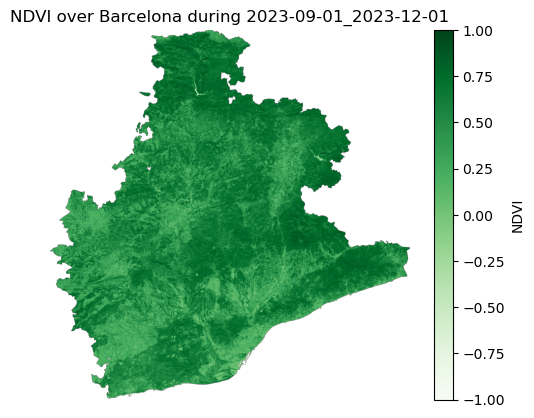

In [161]:
plt.figure()
plt.imshow(real_out_image[0], cmap='Greens', vmin=-1, vmax=1)
plt.colorbar(label="NDVI")
plt.title(f"NDVI over {cityname} during {timeperiod}")
plt.axis('off')
plt.show()

In [40]:
mean_ndvi = np.nanmean(real_out_image[0])
print(f"Mean NDVI over {cityname} during {timeperiod}: {mean_ndvi:.3f}")

Mean NDVI over Barcelona during 2019-12-01_2020-03-01: 0.538


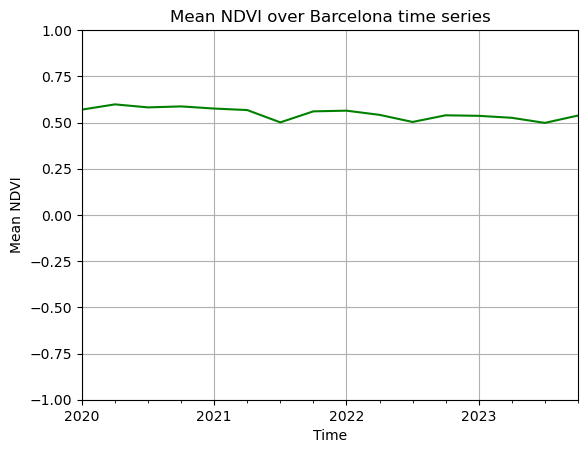

In [41]:
mean_ndvi_time_series = pd.Series(dtype=float)
for year in available_years:
    for quarter in available_quarters:
        timeperiod = quarter2timeperiod(year, quarter)
        filepath  = f"{ndvi_data_folder}{timeperiod}.tif"
        date = pd.to_datetime(timeperiod.split("_")[1])
        current_real_out_image, _ = get_out_image_and_metadata(filepath, one_city_gdf)
        current_mean_ndvi = np.nanmean(current_real_out_image[0])
        mean_ndvi_time_series.loc[date] = current_mean_ndvi

mean_ndvi_time_series = mean_ndvi_time_series.sort_index()

plt.figure()
mean_ndvi_time_series.plot(color='green')
plt.title(f"Mean NDVI over {cityname} time series")
plt.ylabel("Mean NDVI")
plt.xlabel("Time")
plt.ylim(-1, 1)
plt.grid()
plt.show()